# code_014 · Estimation, likelihood and Bayesian updating

**Book:** Chapter 3, section 3.3. **Purpose:** an independent probability/statistics laboratory with synthetic populations and declared measurement models. No numerical result is evidence of structural safety, an empirical causal effect or production reliability.

Use the repository [quickstart](../README.md), select the [pinned environment](../requirements-lock.txt), restart and run every cell. Reference target: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, CPU only on macOS ARM64. All inputs, generators and helper definitions are here. Normal runs require no network, data files, API keys, GPU or private imports. Allow a minute for execution and 30–60 minutes for interpretation/exercises. Actual versions and time appear below and in [run evidence](../CHAPTER_03_EXECUTION.md).

Read predictions before output. Sampling assumptions, priors, numerical simulation budgets and decision margins have different roles; they are not all model hyperparameters. These are scoped concept laboratories, not full estimator-constructor guides. The [traceability guide](../CHAPTER_03_GUIDE.md) maps mechanisms and exercises, and the [stable registry](../CODE_EXAMPLES.md#code_014) preserves this ID. Synthetic algebra/population checks need no learned train/test split; any fitted prediction experiment below states its calibration and assessment boundaries.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import stats,special
from IPython.display import display
START=time.perf_counter();SEED=314
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 314


<a id="likelihood"></a>
## Likelihood is a function of the parameter

Twenty independently sampled comparable components have complete one-year binary outcomes, four positive. Under a common-rate binomial model, log likelihood is log choose(n,s)+s*log(p)+(n-s)*log(1-p). The MLE is s/n. Likelihood is not automatically a normalized probability distribution over p. The same observation model can support different estimation procedures.

**Predict:** if no exceedances occur, is the MLE zero? Does that imply a known zero population rate?


In [2]:
n,s=20,4;p_grid=np.linspace(.0001,.9999,10001)
log_likelihood=stats.binom.logpmf(s,n,p_grid);mle=s/n
assert abs(p_grid[np.argmax(log_likelihood)]-mle)<.0002
assert np.isclose(stats.binom.logpmf(s,n,mle),special.gammaln(n+1)-special.gammaln(s+1)-special.gammaln(n-s+1)+s*np.log(mle)+(n-s)*np.log1p(-mle))
print('MLE:',mle,'maximum grid log likelihood:',log_likelihood.max())
RESULTS['mle']=mle


MLE: 0.2 maximum grid log likelihood: -1.5223460463489054


<a id="updating"></a>
## Collect powers to update the beta prior

The declared prior is Beta(2,18), mean .1. Multiplying by a binomial likelihood adds successes to alpha and nonexceedances to beta. Four out of 20 gives Beta(6,34), mean .15. Another 8/80 gives Beta(14,106), mean .116667. Batch and sequential updates agree only under the unchanged common-rate model. A new material or ascertainment rule may invalidate pooling.

**Predict:** why is the first posterior mean between .1 and .2? What evidence would justify treating the prior as independent information?


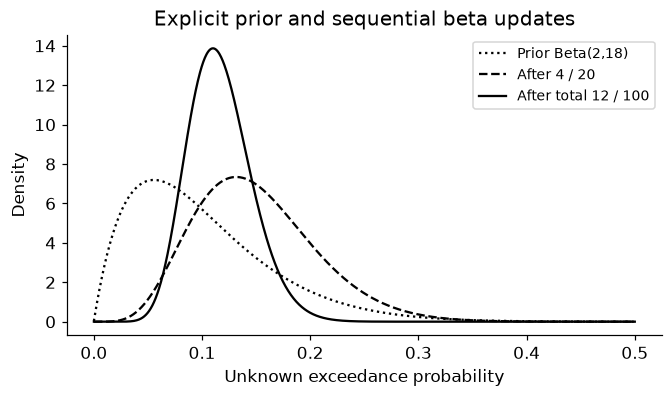

In [3]:
prior=np.array([2.,18.]);first=prior+np.array([s,n-s]);second=first+np.array([8,72]);batch=prior+np.array([12,88])
assert np.array_equal(second,batch) and np.isclose(first[0]/first.sum(),.15)
assert np.isclose(second[0]/second.sum(),14/120)
fig,ax=plt.subplots(figsize=(6,3.5));p_plot=np.linspace(.0001,.5,1000)
for shapes,style,label in [(prior,':','Prior Beta(2,18)'),(first,'--','After 4 / 20'),(second,'-','After total 12 / 100')]:
 ax.plot(p_plot,stats.beta.pdf(p_plot,*shapes),color='black',ls=style,label=label)
ax.set(xlabel='Unknown exceedance probability',ylabel='Density',title='Explicit prior and sequential beta updates');ax.legend(fontsize=9);plt.show()
RESULTS['first_posterior_shapes']=first.tolist();RESULTS['second_posterior_shapes']=second.tolist();RESULTS['posterior_means']=[float(first[0]/first.sum()),float(second[0]/second.sum())]


<a id="credible"></a>
## Parameter quantiles and prior sensitivity

An equal-tailed 95% credible interval contains 95% posterior probability for p under this prior/likelihood. It is not a prediction interval for a future 0-or-1 outcome and does not automatically have 95% repeated-sampling coverage for every fixed p. We compare two predeclared priors; neither is selected to make the result look favorable.

**Predict:** does a uniform Beta(1,1) prior give the same mean as the MLE after 4/20? How does prior influence change after more comparable evidence?


In [4]:
credible=stats.beta.ppf([.025,.975],*first)
assert np.allclose(stats.beta.cdf(credible,*first),[.025,.975])
rows=[]
for label,aa,bb in [('declared',2.,18.),('uniform',1.,1.)]:
 for count,total in [(4,20),(12,100)]:
  post=np.array([aa+count,bb+total-count]);interval=stats.beta.ppf([.025,.975],*post)
  rows.append([label,count,total,post[0]/post.sum(),*interval])
sensitivity=pd.DataFrame(rows,columns=['prior','positive','n','posterior_mean','credible_low','credible_high']);display(sensitivity)
RESULTS['first_95pct_credible_interval']=credible.tolist()


,prior,positive,n,posterior_mean,credible_low,credible_high
0,declared,4,20,0.150000,0.058624,0.274299
1,declared,12,100,0.116667,0.065834,0.179564
2,uniform,4,20,0.227273,0.082176,0.419066
3,uniform,12,100,0.127451,0.070350,0.198345


<a id="predictive"></a>
## Integrate uncertainty over future counts

For ten future comparable components, beta-binomial prediction averages Binomial(10,p) over the posterior Beta(6,34). Compare it with a plug-in Binomial(10,.15). The beta-binomial variance is larger because the future outcomes share uncertainty about p. Parameter uncertainty and individual Bernoulli variation remain distinct.

**Predict:** should either distribution put its probability on fractional observed counts? What happens to the difference as posterior concentration grows at fixed mean?


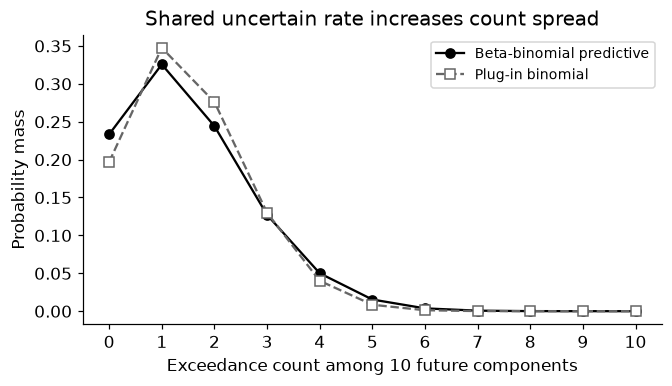

In [5]:
aa,bb=first;m=10;mean_p=aa/(aa+bb);k=np.arange(m+1)
predictive=stats.betabinom.pmf(k,m,aa,bb);plugin=stats.binom.pmf(k,m,mean_p)
expected_var=m*mean_p*(1-mean_p)*(aa+bb+m)/(aa+bb+1)
actual_var=np.sum((k-m*mean_p)**2*predictive)
assert np.isclose(predictive.sum(),1) and np.isclose(np.dot(k,predictive),m*mean_p)
assert np.isclose(actual_var,expected_var) and actual_var>m*mean_p*(1-mean_p)
fig,ax=plt.subplots(figsize=(6,3.4));ax.plot(k,predictive,'ko-',label='Beta-binomial predictive');ax.plot(k,plugin,'s--',color='.4',mfc='white',label='Plug-in binomial')
ax.set(xlabel='Exceedance count among 10 future components',ylabel='Probability mass',xticks=k,title='Shared uncertain rate increases count spread');ax.legend(fontsize=9);plt.show()
RESULTS['future_count_predictive_variance']=float(actual_var);RESULTS['future_count_plugin_variance']=float(m*mean_p*(1-mean_p))


<a id="zero"></a>
## Zero observations of an event are not proof of zero risk

Use a *separate* hypothetical batch with zero exceedances among 20 independent components. A uniform prior gives Beta(1,21); a positive upper quantile remains. A Wilson interval, calculated from the binomial score inversion, also has a positive upper endpoint at zero events. These intervals have different interpretations. The exercise is not an invitation to choose whichever endpoint is more convenient.

**Predict:** why does the naive Wald interval p_hat +/- 1.96*sqrt(p_hat*(1-p_hat)/n) collapse here?


In [6]:
n_zero=20;phat=0.;z=stats.norm.ppf(.975);den=1+z*z/n_zero
center=(phat+z*z/(2*n_zero))/den
half=z*np.sqrt(phat*(1-phat)/n_zero+z*z/(4*n_zero*n_zero))/den
wilson=np.array([center-half,center+half]);posterior_zero=stats.beta.ppf([.025,.975],1,21)
assert np.isclose(wilson[0],0) and wilson[1]>0 and posterior_zero[1]>0
assert phat*(1-phat)/n_zero==0
print('Zero-event Wilson interval:',wilson,'uniform-prior credible interval:',posterior_zero)
RESULTS['zero_event_wilson_interval']=wilson.tolist();RESULTS['zero_event_credible_interval']=posterior_zero.tolist()


Zero-event Wilson interval: [0.         0.16112516] uniform-prior credible interval: [0.00120488 0.16109762]


<a id="exercises"></a>
## Exercises and hints

1. Derive the log-likelihood derivative, then compare posterior mean, posterior mode and MLE after the first batch.
2. Apply both batches in reverse order. Explain why equality is mathematical evidence for the assumed common-rate update, not evidence that the two populations are comparable.
3. Add a strongly concentrated prior and report sensitivity. Do not choose a prior after seeing which conclusion it supports.
4. Replace a perfect binary label with an inspection proxy of known sensitivity/specificity. Derive the observed positive probability; ask what becomes unidentified if these rates are unknown.
5. Simulate repeated independent datasets at fixed p to compare credible-interval and Wilson-interval frequentist coverage, without expecting either to equal its nominal level in every small finite case.

**Hints:** posterior mean uses alpha/(alpha+beta), interior mode uses (alpha-1)/(alpha+beta-2). Prior shape sum is an algebraic weight in the mean formula, not a certificate of previous observations. Count intervals have discrete endpoints and need not achieve exactly the nominal central probability.

**Troubleshooting:** use log likelihood rather than huge products; `ppf` returns parameter quantiles here. Docs: [beta](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.beta.html), [beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html), [NIST binomial interval guidance](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm). Live docs may advance beyond the printed tested version.


In [7]:
summary={'example_id':'code_014','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['binomial likelihood and MLE', 'beta prior and posterior', 'sequential equivalence', 'credible intervals', 'predictive versus parameter uncertainty', 'zero outcomes and prior sensitivity'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["binomial likelihood and MLE", "beta prior and posterior", "sequential equivalence", "credible intervals", "predictive versus parameter uncertainty", "zero outcomes and prior sensitivity"], "elapsed_seconds": 0.162, "example_id": "code_014", "hardware": "Darwin arm64 CPU", "results": {"first_95pct_credible_interval": [0.05862426286078934, 0.2742994104447158], "first_posterior_shapes": [6.0, 34.0], "future_count_plugin_variance": 1.275, "future_count_predictive_variance": 1.5548780487804896, "mle": 0.2, "posterior_means": [0.15, 0.11666666666666667], "second_posterior_shapes": [14.0, 106.0], "zero_event_credible_interval": [0.0012048834483635127, 0.1610976152190796], "zero_event_wilson_interval": [0.0, 0.16112515805281938]}, "seed": 314, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
